In [1]:
include("../src/load_all.jl")

Loaded successfully.


In [14]:
case = IsentropicCase.make_case(nx=40, degree=2, final_time=1)
solution = Solver.raw_solve_2d(case; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case.final_time/20)

(solution.time, solution.number_of_steps, solution.number_of_retries)

step=1 time=0.01851834708884097 dt=0.01851834708884097 retries=0
step=2 time=0.03703562543248056 dt=0.01851727834363959 retries=0
step=3 time=0.05555240533719201 dt=0.018516779904711445 retries=0
step=4 time=0.07406925694117267 dt=0.018516851603980655 retries=0
step=5 time=0.09258674988774841 dt=0.018517492946575745 retries=0
step=6 time=0.11110320626011573 dt=0.018516456372367315 retries=0
step=7 time=0.12961340159055484 dt=0.018510195330439124 retries=0
step=8 time=0.1481179059485058 dt=0.01850450435795095 retries=0
step=9 time=0.16661728923987698 dt=0.018499383291371185 retries=0
step=10 time=0.1851121211482714 dt=0.018494831908394446 retries=0
step=11 time=0.20360297108073147 dt=0.01849084993246005 retries=0
step=12 time=0.22209040810671743 dt=0.018487437025985955 retries=0
step=13 time=0.2405750008833991 dt=0.018484592776681668 retries=0
step=14 time=0.25905731756422545 dt=0.018482316680826352 retries=0
step=15 time=0.2775379256908125 dt=0.018480608126587 retries=0
step=16 time=0.

(1.0, 55, 0)

In [15]:
Diagnostics.conservation_report(solution)

(initial_total_ls = [64.46798598878988, 32.878672854282605, 32.878672854282605, 22.778688382705692], final_total_ls = [64.46798598878956, 32.87867285428272, 32.8786728542824, 22.77868838270554], change_ls = [-3.126388037344441e-13, 1.1368683772161603e-13, -2.0605739337042905e-13, -1.5276668818842154e-13], boundary_change_ls = [8.68562204856695e-21, 3.589653758722884e-18, 1.5917435879735764e-18, 3.275331275853922e-17], balance_error_ls = [-3.1263881242006614e-13, 1.1368324806785731e-13, -2.0605898511401704e-13, -1.5279944150118008e-13])

In [16]:
Diagnostics.smooth_error_norms(solution.state,case,solution.time)

(L1_ls = [5.0236955978707896e-6, 4.860941081487443e-6, 4.854559542851882e-6, 4.663752585433516e-6], L2_ls = [7.965614475324443e-6, 7.760168261426699e-6, 7.76018065057168e-6, 7.708577095403543e-6], Linf_ls = [0.00011233426896217757, 0.00011469614474923784, 0.00011469615458631344, 0.00012044292298979409], total_area = 157.9136704174282)

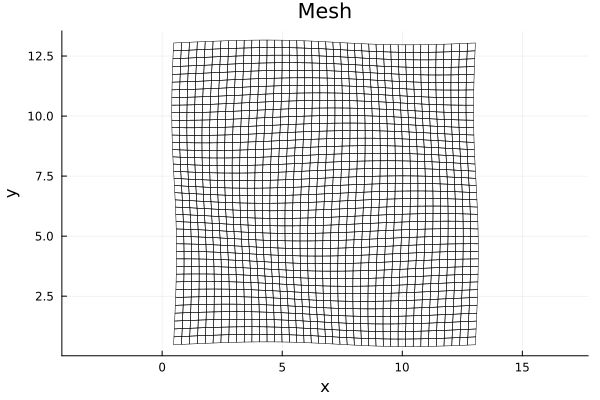

In [17]:
display(Visualization.plot_mesh(solution.state,case.mesh))

[ Info: Saved animation to C:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasedensity.gif


Plots.AnimatedGif("C:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasedensity.gif")
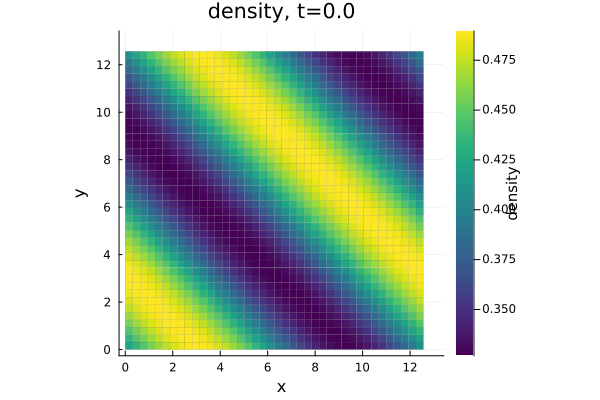

[ Info: Saved animation to C:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasepressure.gif


Plots.AnimatedGif("C:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasepressure.gif")
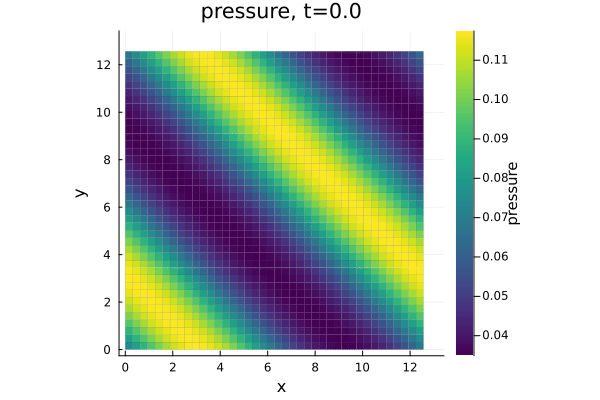

[ Info: Saved animation to C:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasevelocity_x.gif


Plots.AnimatedGif("C:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasevelocity_x.gif")
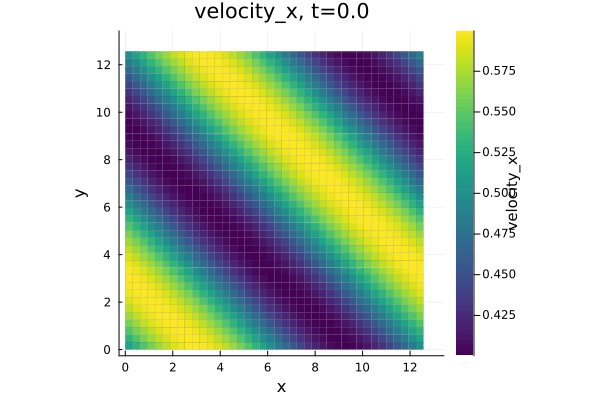

[ Info: Saved animation to C:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasevelocity_y.gif


Plots.AnimatedGif("C:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasevelocity_y.gif")
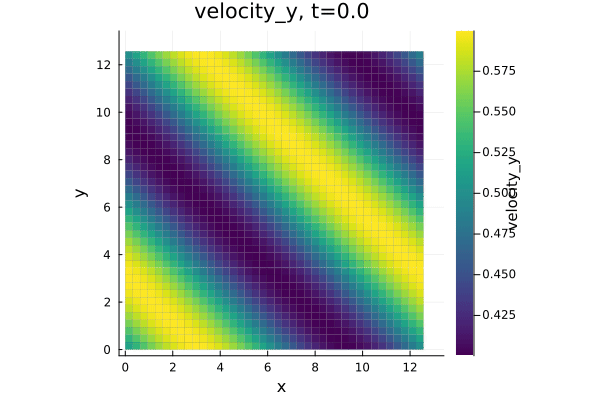

In [25]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution,
        "../results/IsentropicCase$(field).gif";
        field = field,
        fps = 10,
    )
    display(gif_result)
end
# plot this is very very slow!!!!!!!!!!!

In [2]:
function Isentropic_case_builder(nx, degree, final_time=1)
    
    if degree <= 1
        cfl = 0.5
    end
    if degree == 2
        cfl = 0.3
    end
    if degree == 3
        cfl = 0.1
    end 
    
    return IsentropicCase.make_case(
        nx = nx,
        degree = degree,
        final_time = final_time,
        cfl = 0.05,
    )
end

Isentropic_case_builder (generic function with 2 methods)

In [ ]:
# Diagnostics.convergence_study_data
function convergence_study_data(case_builder; mesh_sizes_ls=[4, 8, 16], degree=2,
                        final_time=1, time_method=:RK4, dt_max=Inf)

    rows_ls = NamedTuple[]

    for nx in mesh_sizes_ls
        case = case_builder(nx, degree, final_time) # case::Discretization.DGCase
        solution = Solver.raw_solve_2d(case; time_method=time_method, dt_max=dt_max)
        errors = Diagnostics.smooth_error_norms(solution.state, case, solution.time)
        order_ls = fill(NaN, 4)
        if !isempty(rows_ls)
            previous = rows_ls[end]
            for component_index in 1:4
                if previous.L2_ls[component_index] > 0 && errors.L2_ls[component_index] > 0
                    order_ls[component_index] = log(previous.L2_ls[component_index] / errors.L2_ls[component_index]) / log(nx / previous.nx)
                end
            end
        end

        # first one just push 
        push!(rows_ls, (nx=nx, degree=degree, L1_ls=errors.L1_ls, L2_ls=errors.L2_ls,
                    Linf_ls=errors.Linf_ls, order_ls=order_ls,
                    number_of_steps=solution.number_of_steps, number_of_retries=solution.number_of_retries))
    end

    return rows_ls

end
converge_data = convergence_study_data(Isentropic_case_builder) # 36 Seconds

3-element Vector{NamedTuple}:
 (nx = 4, degree = 2, L1_ls = [0.004395642611712015, 0.0039507172557761575, 0.003959650068691601, 0.00410227267701272], L2_ls = [0.006054888136377305, 0.005363256105994582, 0.00536296444546132, 0.005564703435969277], Linf_ls = [0.03808393703260149, 0.040003231034305864, 0.0400035921945604, 0.04451478879190329], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 2, L1_ls = [0.0005340631376989458, 0.0005373557760145697, 0.0005335453917175913, 0.0005271133096690418], L2_ls = [0.0008206045911706109, 0.0008076745737862439, 0.0008077192682743987, 0.0008319106616269077], Linf_ls = [0.008325737118856091, 0.009523463570581703, 0.009522616500588998, 0.010849967339936595], order_ls = [2.8833411754313505, 2.7312631184274645, 2.7311048281802606, 2.741804291290495], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 2, L1_ls = [7.418062423319679e-5, 7.295891129728892e-5, 7.271027022239787e-5, 7.080357777004782e

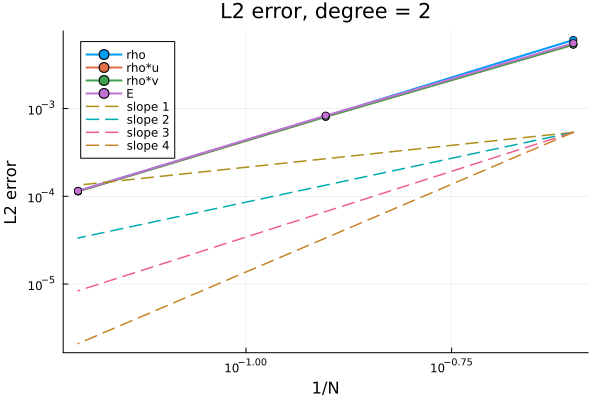

3-element Vector{NamedTuple}:
 (nx = 4, degree = 2, L1_ls = [0.004395642611712015, 0.0039507172557761575, 0.003959650068691601, 0.00410227267701272], L2_ls = [0.006054888136377305, 0.005363256105994582, 0.00536296444546132, 0.005564703435969277], Linf_ls = [0.03808393703260149, 0.040003231034305864, 0.0400035921945604, 0.04451478879190329], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 2, L1_ls = [0.0005340631376989458, 0.0005373557760145697, 0.0005335453917175913, 0.0005271133096690418], L2_ls = [0.0008206045911706109, 0.0008076745737862439, 0.0008077192682743987, 0.0008319106616269077], Linf_ls = [0.008325737118856091, 0.009523463570581703, 0.009522616500588998, 0.010849967339936595], order_ls = [2.8833411754313505, 2.7312631184274645, 2.7311048281802606, 2.741804291290495], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 2, L1_ls = [7.418062423319679e-5, 7.295891129728892e-5, 7.271027022239787e-5, 7.080357777004782e

In [4]:
Diagnostics.convergence_study_plot(converge_data)

In [5]:
converge_data = convergence_study_data(Isentropic_case_builder, mesh_sizes_ls=[4, 8, 16], degree=3,final_time=1, time_method=:SSPRK3, dt_max=Inf)
# 36 Seconds

3-element Vector{NamedTuple}:
 (nx = 4, degree = 3, L1_ls = [0.0011061334119290326, 0.0009916645956481766, 0.000990397610559388, 0.0009695693650513339], L2_ls = [0.0016052863550181527, 0.0013693551597690062, 0.0013692197511822283, 0.001275024019208653], Linf_ls = [0.02121567593153134, 0.014431877102534851, 0.014422371709486431, 0.011402523576626994], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 3, L1_ls = [9.328309296892975e-5, 9.1950018113714e-5, 9.30098914230472e-5, 9.445243565629736e-5], L2_ls = [0.0001459379777414287, 0.0001457971507554142, 0.00014579685111759208, 0.00014952605925269016], Linf_ls = [0.0019208077786356248, 0.0023899686001825904, 0.0023900357246909865, 0.0026776444608495875], order_ls = [3.459403399136423, 3.231462245385594, 3.231322542521508, 3.092055582272662], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 3, L1_ls = [6.662090809735492e-6, 6.729885449786294e-6, 6.753580566564245e-6, 6.5389154630

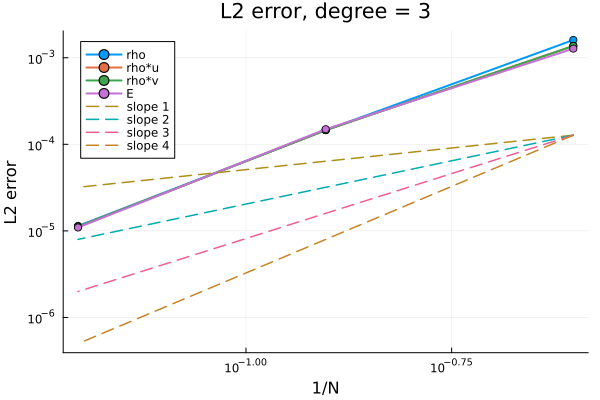

3-element Vector{NamedTuple}:
 (nx = 4, degree = 3, L1_ls = [0.0011061334119290326, 0.0009916645956481766, 0.000990397610559388, 0.0009695693650513339], L2_ls = [0.0016052863550181527, 0.0013693551597690062, 0.0013692197511822283, 0.001275024019208653], Linf_ls = [0.02121567593153134, 0.014431877102534851, 0.014422371709486431, 0.011402523576626994], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 3, L1_ls = [9.328309296892975e-5, 9.1950018113714e-5, 9.30098914230472e-5, 9.445243565629736e-5], L2_ls = [0.0001459379777414287, 0.0001457971507554142, 0.00014579685111759208, 0.00014952605925269016], Linf_ls = [0.0019208077786356248, 0.0023899686001825904, 0.0023900357246909865, 0.0026776444608495875], order_ls = [3.459403399136423, 3.231462245385594, 3.231322542521508, 3.092055582272662], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 3, L1_ls = [6.662090809735492e-6, 6.729885449786294e-6, 6.753580566564245e-6, 6.5389154630

In [6]:
Diagnostics.convergence_study_plot(converge_data)